# 04 — Nhãn phương tiện di chuyển (transportation mode)

Câu hỏi:
1. Bao nhiêu user / điểm / thời lượng có nhãn? Phân bố các loại phương tiện?
2. Chất lượng nhãn: khoảng nhãn chồng lấn, nhãn không có điểm GPS, nhãn "lạ" (tốc độ không hợp với mode).
3. Đặc trưng tốc độ, sampling rate theo mode → ngưỡng tốc độ hợp lý cho lọc outlier và cho phân biệt stay vs move.
4. Mode theo giờ trong ngày, chuỗi chuyển mode.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils import add_geo, add_kinematics, load_labels, load_points, savefig, setup_style

setup_style()
labels = load_labels()
labels["duration_min"] = (labels.end_utc - labels.start_utc).dt.total_seconds() / 60
pts = load_points(["user", "traj_id", "lat", "lon", "ts_utc", "mode"])
print(labels.shape, labels.user.nunique())
labels.head()

(14718, 5) 69


,user,start_utc,end_utc,mode,duration_min
0,10,2007-06-26 11:32:29,2007-06-26 11:40:29,bus,8.0000
1,10,2008-03-28 14:52:54,2008-03-28 15:59:59,train,67.0833
2,10,2008-03-28 16:00:00,2008-03-28 22:02:00,train,362.0000
3,10,2008-03-29 01:27:50,2008-03-29 15:59:59,train,872.1500
4,10,2008-03-29 16:00:00,2008-03-30 15:59:59,train,"1,439.9833"


## 1. Tổng quan nhãn

In [2]:
lab_users = labels.user.unique()
in_lab_user = pts.user.isin(lab_users)
s = pd.Series({
    "User có nhãn / tổng user": f"{len(lab_users)} / {pts.user.nunique()}",
    "Số đoạn nhãn": len(labels),
    "Tổng giờ được gán nhãn": round(labels.duration_min.sum() / 60),
    "% điểm có nhãn (toàn bộ)": f"{pts['mode'].notna().mean():.2%}",
    "% điểm của user có nhãn": f"{in_lab_user.mean():.2%}",
    "% điểm có nhãn (trong user có nhãn)": f"{pts.loc[in_lab_user, 'mode'].notna().mean():.2%}",
})
s.to_frame("giá trị")

,giá trị
User có nhãn / tổng user,69 / 182
Số đoạn nhãn,14718
Tổng giờ được gán nhãn,12953
% điểm có nhãn (toàn bộ),21.84%
% điểm của user có nhãn,50.32%
% điểm có nhãn (trong user có nhãn),43.41%


In [3]:
mode_tbl = pd.DataFrame({
    "segments": labels["mode"].value_counts(),
    "hours": labels.groupby("mode").duration_min.sum() / 60,
    "users": labels.groupby("mode").user.nunique(),
    "points": pts["mode"].value_counts(),
}).fillna(0).sort_values("points", ascending=False)
for c in ["segments", "hours", "points"]:
    mode_tbl[f"%{c}"] = mode_tbl[c] / mode_tbl[c].sum() * 100
mode_tbl.round(2)

,segments,hours,users,points,%segments,%hours,%points
mode,,,,,,,
walk,6460,"5,460.5000",63,1588314,43.8900,42.1600,29.2300
bus,2853,"1,507.0500",51,1277850,19.3800,11.6300,23.5200
bike,2089,"2,410.2700",40,949336,14.1900,18.6100,17.4700
train,299,745.4400,20,561031,2.0300,5.7500,10.3200
car,993,"1,725.1400",40,513475,6.7500,13.3200,9.4500
subway,813,396.3300,27,286649,5.5200,3.0600,5.2800
taxi,1179,659.0900,35,242369,8.0100,5.0900,4.4600
airplane,17,40.8000,6,9193,0.1200,0.3100,0.1700
boat,7,4.6500,4,3566,0.0500,0.0400,0.0700


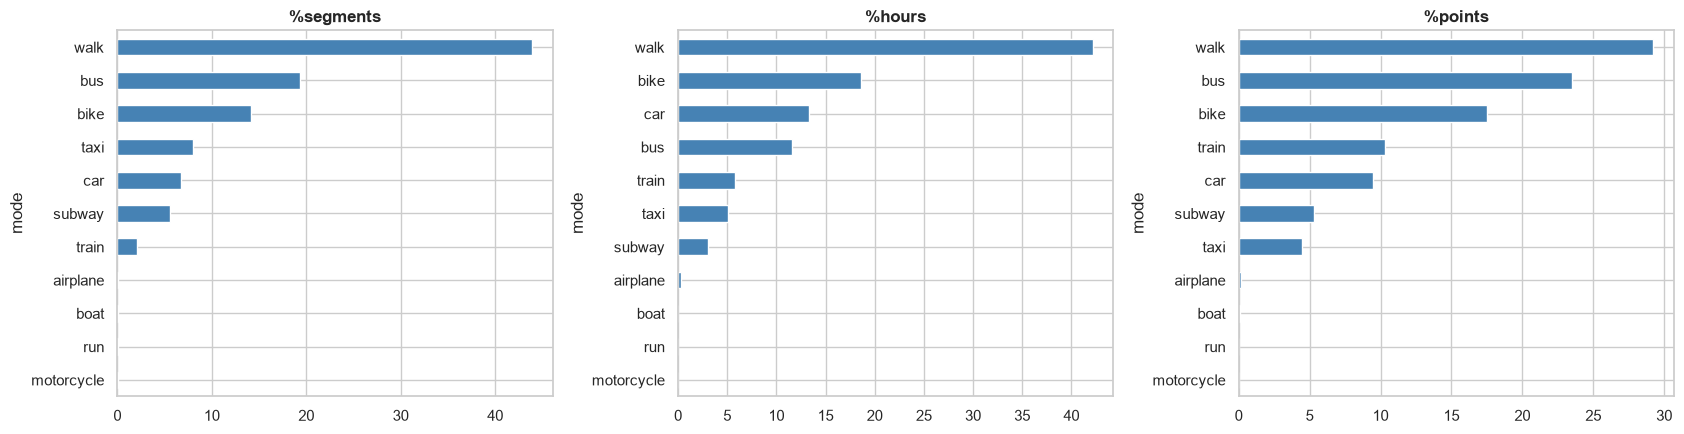

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ["%segments", "%hours", "%points"]):
    mode_tbl[c].sort_values().plot.barh(ax=ax, color="steelblue"); ax.set_title(c)
plt.tight_layout(); savefig("04_mode_share"); plt.show()

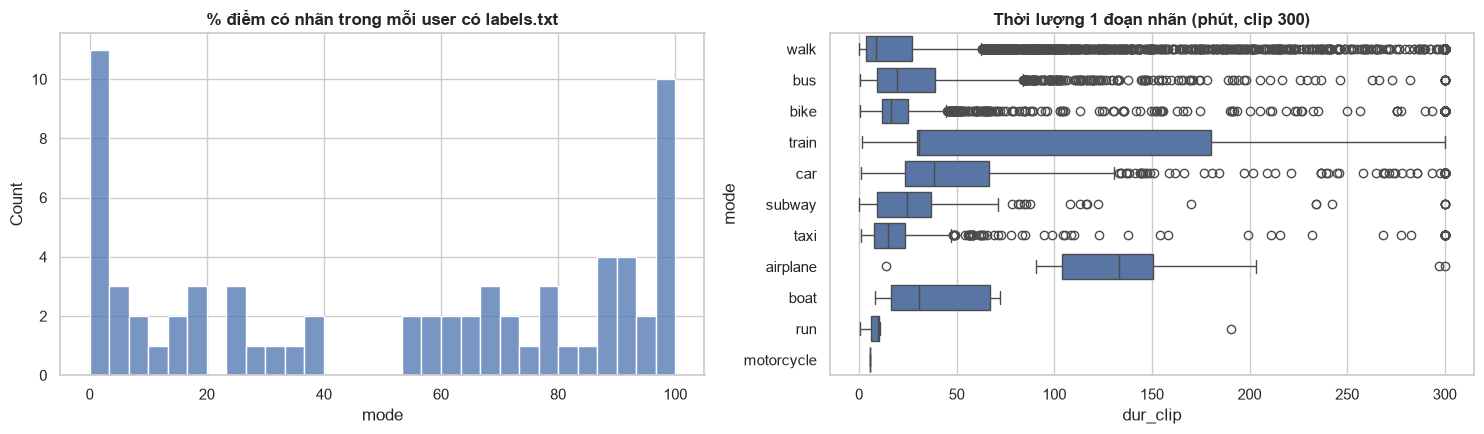

In [5]:
per_user_lab = pts[in_lab_user].groupby("user")["mode"].apply(lambda s: s.notna().mean() * 100)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(per_user_lab, bins=30, ax=ax[0]); ax[0].set_title("% điểm có nhãn trong mỗi user có labels.txt")
sns.boxplot(data=labels.assign(dur_clip=labels.duration_min.clip(upper=300)), y="mode", x="dur_clip", ax=ax[1], order=mode_tbl.index)
ax[1].set_title("Thời lượng 1 đoạn nhãn (phút, clip 300)")
plt.tight_layout(); savefig("04_label_coverage"); plt.show()

**Insight:** nhãn mode chỉ có ở 69/182 user (~38%), phủ ~43% số điểm của các user này (~22% toàn bộ điểm); `walk`, `bus`, `bike` chiếm phần lớn. `motorcycle`, `run`, `boat`
rất hiếm → nếu dùng nhãn này nên gộp nhóm (vd. car+taxi, train+subway) hoặc bỏ lớp hiếm. **Không có nhãn home/office.**

## 2. Chất lượng nhãn

In [6]:
lab = labels.sort_values(["user", "start_utc"]).reset_index(drop=True)
lab["prev_end"] = lab.groupby("user").end_utc.shift()
lab["overlap_s"] = (lab.prev_end - lab.start_utc).dt.total_seconds()
lab["gap_to_prev_s"] = -lab.overlap_s
q = pd.Series({
    "end < start": (lab.end_utc < lab.start_utc).sum(),
    "duration = 0": (lab.duration_min == 0).sum(),
    "duration > 12h": (lab.duration_min > 720).sum(),
    "chồng lấn với đoạn trước": (lab.overlap_s > 0).sum(),
    "nối liền đoạn trước (gap = 0)": (lab.overlap_s == 0).sum(),
})
q.to_frame("số đoạn")

,số đoạn
end < start,0
duration = 0,0
duration > 12h,230
chồng lấn với đoạn trước,149
nối liền đoạn trước (gap = 0),1754


In [7]:
# Mỗi đoạn nhãn có bao nhiêu điểm GPS thực sự nằm trong?
p_lab = pts[in_lab_user][["user", "ts_utc"]].sort_values("ts_utc")
counts = []
for u, g in lab.groupby("user"):
    t = np.sort(p_lab.loc[p_lab.user == u, "ts_utc"].to_numpy())
    a = np.searchsorted(t, g.start_utc.to_numpy(), "left"); b = np.searchsorted(t, g.end_utc.to_numpy(), "right")
    counts.append(pd.Series(b - a, index=g.index))
lab["n_points"] = pd.concat(counts)
lab["pts_per_min"] = lab.n_points / lab.duration_min.replace(0, np.nan)
print(f"Đoạn nhãn KHÔNG có điểm GPS nào: {(lab.n_points == 0).sum()} ({(lab.n_points == 0).mean():.1%})")
lab.groupby("mode").agg(segments=("n_points", "size"), empty_share=("n_points", lambda s: (s == 0).mean()),
                        median_pts_per_min=("pts_per_min", "median")).sort_values("segments", ascending=False)

Đoạn nhãn KHÔNG có điểm GPS nào: 5102 (34.7%)


,segments,empty_share,median_pts_per_min
mode,,,
walk,6460,0.3745,5.6212
bus,2853,0.3453,11.8898
bike,2089,0.2480,23.4343
taxi,1179,0.5581,0.0000
car,993,0.2075,9.7490
subway,813,0.2362,8.9548
train,299,0.3980,1.0224
airplane,17,0.1765,3.2089
boat,7,0.0000,4.3299


## 3. Tốc độ & sampling theo mode

In [8]:
pts = pts.sort_values(["user", "traj_id", "ts_utc"], kind="stable").reset_index(drop=True)
pts["traj_key"] = pts.user.astype(str) + "_" + pts.traj_id.astype(str)
pts = add_kinematics(pts)
lp = pts[pts["mode"].notna() & (pts.dt_s > 0)].copy()
lp["mode"] = lp["mode"].cat.remove_unused_categories()
spd = lp.groupby("mode", observed=True).speed_kmh.describe(percentiles=[.05, .25, .5, .75, .95, .99])
spd["med_dt_s"] = lp.groupby("mode", observed=True).dt_s.median()
spd.sort_values("50%")

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,med_dt_s
mode,,,,,,,,,,,,
boat,"3,564.0000",25.2702,31.4898,0.0000,1.2300,2.2306,3.6903,69.4037,74.5203,75.3510,336.2990,2.0000
walk,"1,337,209.0000",5.6826,14.5136,0.0000,0.2002,2.2150,4.1179,6.1005,14.8269,42.0088,"9,415.6839",2.0000
run,"1,974.0000",6.0953,5.2897,0.0000,0.4907,2.8680,4.7439,8.1237,14.6272,25.8454,55.1120,1.0000
bike,"775,919.0000",11.8286,10.7657,0.0000,0.7564,6.6494,11.2371,15.2146,23.5431,41.7269,"2,556.5120",2.0000
bus,"1,200,419.0000",21.4511,21.1573,0.0000,0.3661,4.1930,16.9410,33.6816,57.9806,90.4973,"2,765.7637",2.0000
motorcycle,338.0000,22.9203,11.0689,0.1537,5.5662,13.3750,22.9420,33.5160,37.3793,39.0639,48.2040,2.0000
car,"504,430.0000",36.6018,31.7587,0.0000,0.7420,9.4384,30.2311,56.4683,93.5601,119.5933,"2,515.2546",2.0000
taxi,"210,956.0000",32.8359,25.3984,0.0000,0.3066,9.2205,31.7062,51.1791,72.5277,104.5809,"1,469.4082",2.0000
subway,"250,798.0000",39.9067,31.4295,0.0000,1.3951,5.7565,50.2585,65.5442,74.5629,94.3770,"3,776.0764",2.0000


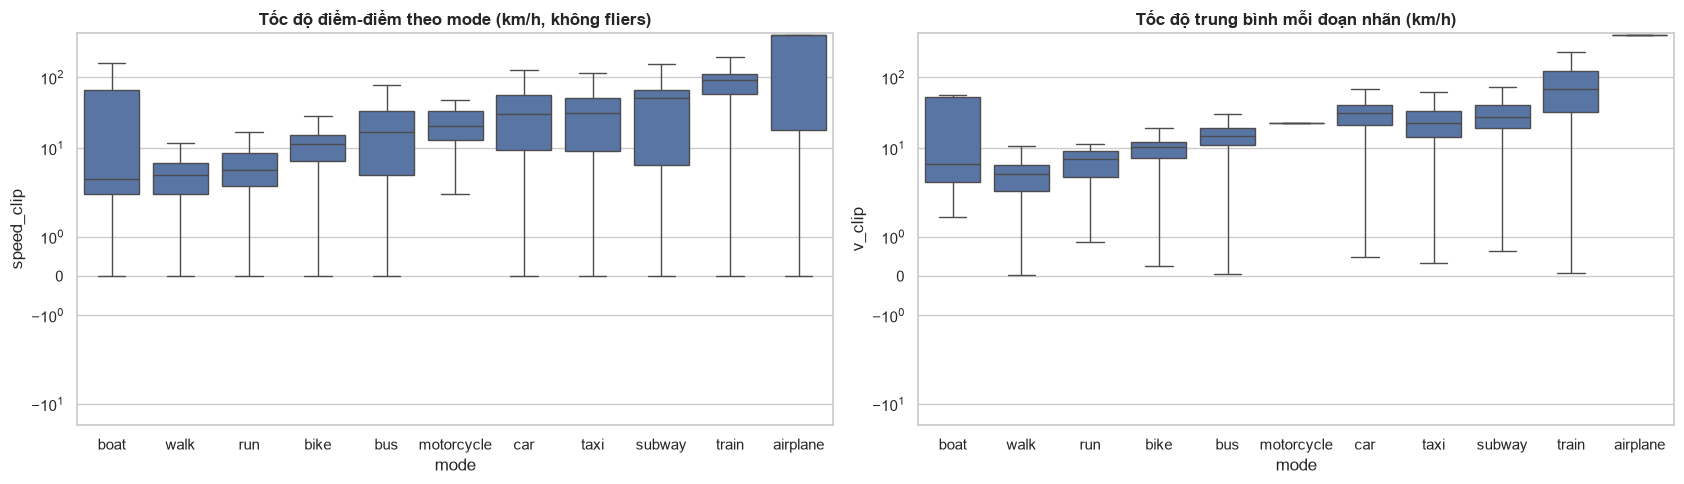

,count,mean,std,min,5%,50%,95%,max
mode,,,,,,,,
airplane,14.0000,582.2698,223.3156,310.9246,338.5827,527.8068,912.9651,"1,133.7735"
bike,"1,555.0000",9.7261,5.0271,0.2490,1.2570,10.3727,15.5792,96.7306
boat,7.0000,25.1512,27.0680,1.5140,1.7968,5.9154,55.4958,55.8838
bus,"1,854.0000",16.0906,9.7787,0.0514,3.6648,14.7458,29.8467,127.5984
car,787.0000,31.7903,16.9240,0.4757,5.8717,31.5691,57.2245,138.8922
motorcycle,2.0000,22.9203,0.0000,22.9203,22.9203,22.9203,22.9203,22.9203
run,3.0000,6.3763,5.2255,0.8711,1.4830,6.9899,10.8401,11.2679
subway,609.0000,29.2674,14.0194,0.6361,7.4070,27.8433,49.3221,112.1761
taxi,518.0000,24.9063,15.1497,0.3373,3.6431,22.3961,51.5652,146.6752


In [9]:
order = spd.sort_values("50%").index
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
lp["speed_clip"] = lp.speed_kmh.clip(upper=400)
sns.boxplot(data=lp.sample(2_000_000, random_state=0), x="mode", y="speed_clip",
            order=order, showfliers=False, ax=axes[0])
axes[0].set_yscale("symlog"); axes[0].set_title("Tốc độ điểm-điểm theo mode (km/h, không fliers)")
# Tốc độ trung bình theo đoạn nhãn (ổn định hơn tốc độ điểm-điểm)
lp["seg"] = pd.merge_asof(lp[["ts_utc", "user"]].reset_index().sort_values("ts_utc"),
                          lab[["user", "start_utc"]].reset_index().rename(columns={"index": "seg"}).sort_values("start_utc"),
                          left_on="ts_utc", right_on="start_utc", by="user").set_index("index")["seg"]
seg = lp.groupby("seg").agg(mode=("mode", "first"), dist=("dist_m", "sum"), dur=("dt_s", "sum"))
seg = seg[seg.dur > 60]
seg["v_kmh"] = seg.dist / seg.dur * 3.6
seg["v_clip"] = seg.v_kmh.clip(upper=400)
sns.boxplot(data=seg, x="mode", y="v_clip", order=order, showfliers=False, ax=axes[1])
axes[1].set_yscale("symlog"); axes[1].set_title("Tốc độ trung bình mỗi đoạn nhãn (km/h)")
plt.tight_layout(); savefig("04_speed_by_mode"); plt.show()
seg.groupby("mode", observed=True).v_kmh.describe(percentiles=[.05, .5, .95])

In [10]:
# Tỉ lệ điểm "phi lý" theo mode → gợi ý mức nhiễu của nhãn & GPS
implaus = {"walk": 15, "run": 30, "bike": 40, "bus": 120, "car": 200, "taxi": 200, "subway": 150,
           "train": 400, "motorcycle": 200, "boat": 100, "airplane": 1200}
lp["over"] = lp.speed_kmh > lp["mode"].astype(str).map(implaus)
(lp.groupby("mode", observed=True).over.mean() * 100).sort_values(ascending=False).round(2).to_frame("% điểm vượt ngưỡng phi lý")

,% điểm vượt ngưỡng phi lý
mode,
walk,4.9200
bike,1.1300
run,0.9600
boat,0.1700
subway,0.1400
car,0.1000
bus,0.0900
airplane,0.0100
taxi,0.0100


In [11]:
# Tỉ lệ điểm gần đứng yên (< 1 km/h) theo mode → mức "dừng" xen trong các chuyến đi (đèn đỏ, chờ bus…)
(lp.assign(still=lp.speed_kmh < 1).groupby("mode", observed=True).still.mean() * 100).round(1).sort_values().to_frame("% điểm < 1 km/h")

,% điểm < 1 km/h
mode,
train,0.8000
motorcycle,1.2000
boat,3.2000
subway,3.7000
car,5.7000
bike,6.0000
airplane,7.4000
run,7.9000
taxi,9.3000


**Insight:**
- Tốc độ điểm-điểm rất nhiễu (dt 1–2s) → nên làm mượt/tính trên cửa sổ hoặc dùng tốc độ đoạn khi phân biệt stay/move.
- `walk` có median ~4–5 km/h; ngưỡng **stay** tự nhiên khoảng < 1–2 km/h kéo dài. Ngay cả trong `bus/car` vẫn có nhiều điểm gần đứng yên
  (kẹt xe, đèn đỏ) → stay-point cần ngưỡng **thời gian tối thiểu** (vd. ≥ 20–30 phút) để không nhầm kẹt xe là điểm dừng.
- ~35% đoạn nhãn **không có điểm GPS nào** (đặc biệt `taxi` > 50%) → nhãn được ghi độc lập với log GPS; join nhãn ↔ điểm luôn phải kiểm tra coverage.
- Có đoạn nhãn kéo dài > 12h (vd. user 10 đi `train` nhiều ngày) và 149 đoạn chồng lấn → cần làm sạch nhãn nếu dùng.
- `walk` có ~5% điểm > 15 km/h → nhiễu GPS/nhãn đáng kể ngay cả trong dữ liệu có nhãn.
- Ngưỡng tốc độ lọc outlier toàn cục hợp lý ~ 300–400 km/h (train cao tốc), trừ `airplane`.

## 4. Mode theo giờ local & chuỗi chuyển mode

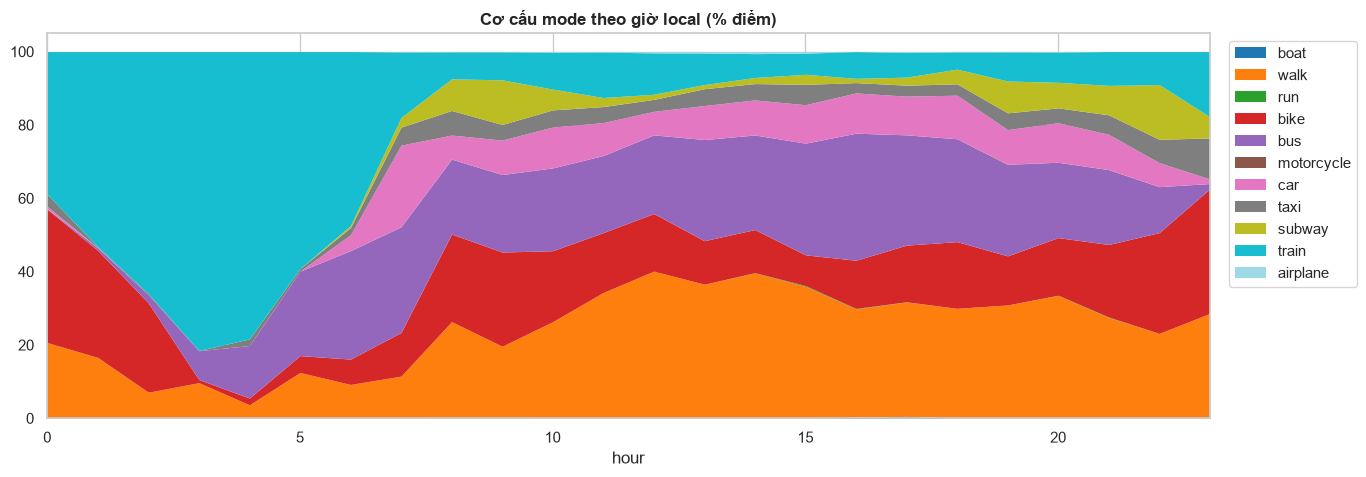

In [12]:
lab_pts = add_geo(pts[pts["mode"].notna()][["lat", "lon", "ts_utc", "mode"]].copy())
lab_pts["hour"] = lab_pts.ts_local.dt.hour
mh = pd.crosstab(lab_pts.hour, lab_pts["mode"], normalize="index") * 100
mh = mh[[m for m in order if m in mh.columns]]
mh.plot.area(figsize=(15, 5), cmap="tab20", lw=0)
plt.title("Cơ cấu mode theo giờ local (% điểm)"); plt.legend(bbox_to_anchor=(1.01, 1)); plt.xlim(0, 23)
savefig("04_mode_by_hour"); plt.show()

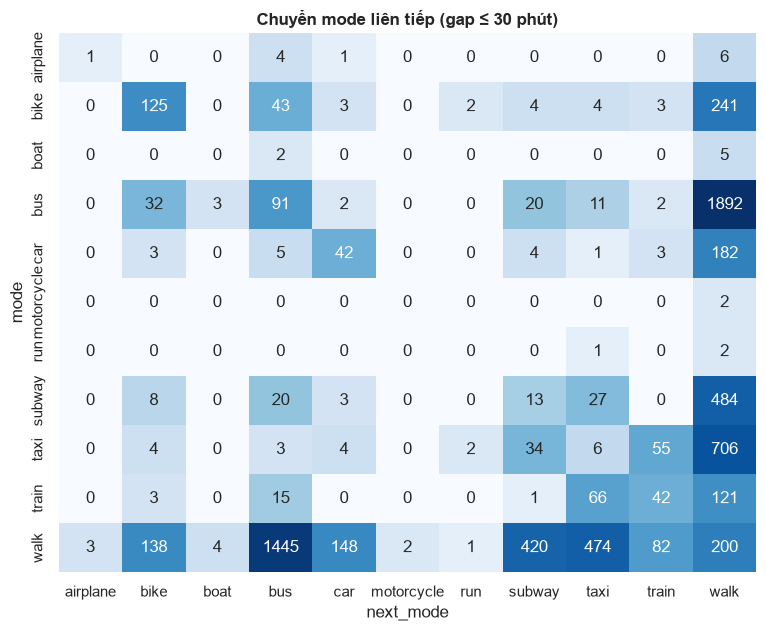

In [13]:
lab["next_mode"] = lab.groupby("user")["mode"].shift(-1)
lab["gap_next_min"] = (lab.groupby("user").start_utc.shift(-1) - lab.end_utc).dt.total_seconds() / 60
tr = lab[lab.gap_next_min.between(0, 30)]
trans = pd.crosstab(tr["mode"], tr.next_mode)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(np.log1p(trans), annot=trans, fmt="d", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Chuyển mode liên tiếp (gap ≤ 30 phút)"); savefig("04_mode_transition"); plt.show()

**Insight:** `walk` là "keo nối" giữa mọi phương tiện khác (bus→walk→subway…). Điểm chuyển `walk ↔ phương tiện` thường là trạm dừng ngắn,
không phải stay-point có ý nghĩa → stay-point detection cần ngưỡng thời gian đủ lớn để loại các điểm chuyển tiếp này.